<a href="https://colab.research.google.com/github/MKSakthi/L02-hedonic-pricing/blob/main/Team_2_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Meena Sakthi, BAI Yongqi, Abdul-Salam Gidado, Justin Diamond

**Date:** 11/09/26

Original dataset shape: (16814, 19)
Missing categorical values:
hvac_description        7
exterior                1
interior                7
roof_cover              8
waterfront_type     16261
view_quality        15895
utility_sewer           0
dtype: int64
Rows in multi-building sales: 386
Multi-building rows among the 10 highest prices: 6
Number of duplicate rows: 38
Number of suspicious observations removed: 103
Cleaned dataset shape: (16287, 19)
Remaining missing values: 0
count      16287.0
mean      456918.0
std       200996.0
min        25000.0
25%       349000.0
50%       415500.0
75%       520000.0
max      3500000.0
Name: sale_price, dtype: float64


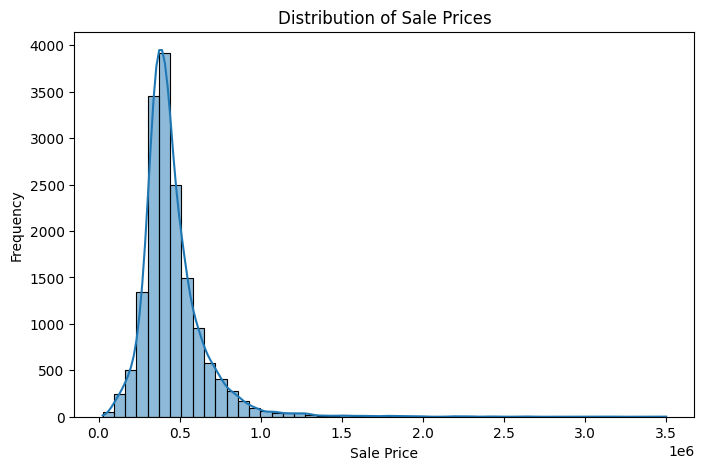

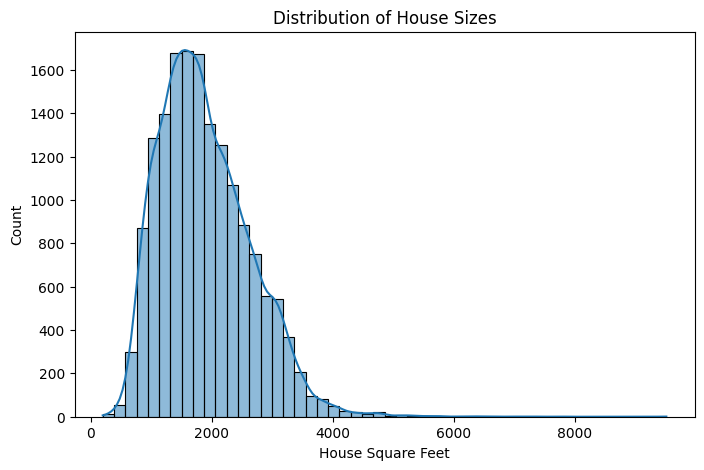

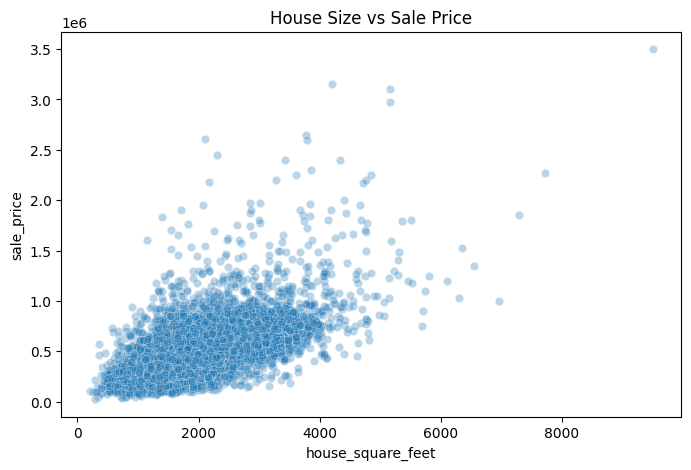

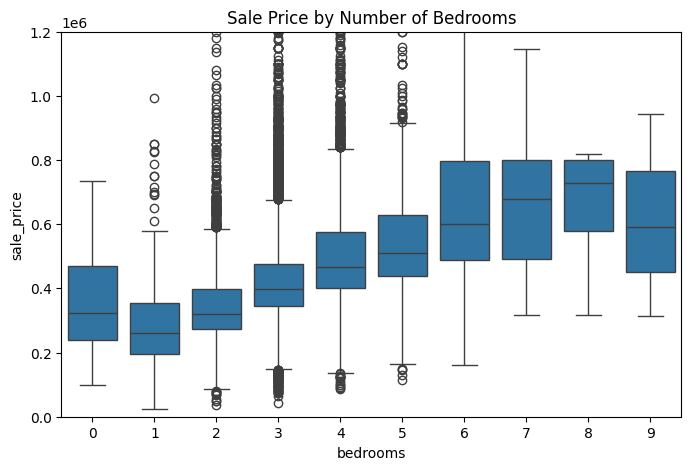

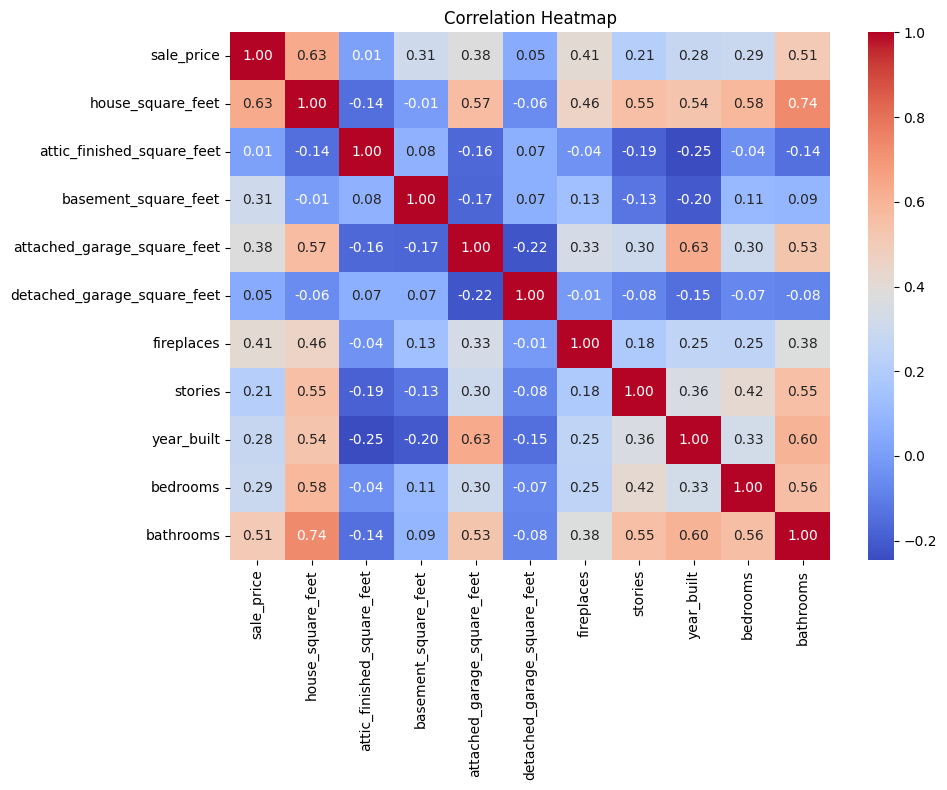

In [ ]:
# Question 1 - Cleaning and EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/L02-hedonic-pricing/data/pierce_county_house_sales.csv")

# Cleaning the data
df["sale_date"] = pd.to_datetime(df["sale_date"])

categoricalcols = [
"hvac_description",
"exterior",
"interior",
"roof_cover",
"waterfront_type",
"view_quality",
"utility_sewer"
]

print("Original dataset shape:", df.shape)
print("Missing categorical values:")
print(df[categoricalcols].isnull().sum())

# A sale of several buildings shows up as back-to-back rows with the same date and price,
# so every building in it carries the price of the whole sale
same_sale = (df["sale_date"] == df["sale_date"].shift()) & (df["sale_price"] == df["sale_price"].shift())
multi_building = same_sale | same_sale.shift(-1, fill_value=False)
print("Rows in multi-building sales:", multi_building.sum())
print("Multi-building rows among the 10 highest prices:", multi_building[df["sale_price"].nlargest(10).index].sum())
print("Number of duplicate rows:", df.loc[~multi_building].duplicated().sum())

# Remove multi-building sales and duplicate rows
df_clean = df.loc[~multi_building].drop_duplicates().copy()

# Remove suspicious observations
price_per_sqft = df_clean["sale_price"] / df_clean["house_square_feet"]
suspicious = (
    (df_clean["sale_price"] < 10000)
    | (df_clean["house_square_feet"] < 200)
    | (df_clean["year_built"] > df_clean["sale_date"].dt.year)
    | (price_per_sqft < 50)
    | (price_per_sqft > 2000)
    | (df_clean["bedrooms"] > 20)
)

print("Number of suspicious observations removed:", suspicious.sum())
df_clean = df_clean.loc[~suspicious].copy()

# A blank waterfront type or view means the house has none
df_clean["waterfront_type"] = df_clean["waterfront_type"].fillna("None")
df_clean["view_quality"] = df_clean["view_quality"].fillna("None")
df_clean["hvac_description"] = df_clean["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# Fill the few remaining missing categorical values
for col in categoricalcols:
    df_clean[col] = df_clean[col].fillna("Not recorded")

# Final cleaning checks
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print(df_clean["sale_price"].describe().round(0))

# Distribution of sale prices
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["sale_price"], bins=50, kde=True)
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# Distribution of house sizes
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["house_square_feet"], bins=50, kde=True)
plt.title("Distribution of House Sizes")
plt.xlabel("House Square Feet")
plt.show()

# House size vs sale price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="house_square_feet",
    y="sale_price",
    alpha=0.3
)
plt.title("House Size vs Sale Price")
plt.show()

# Bedrooms vs sale price
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="bedrooms", y="sale_price")
plt.ylim(0, df_clean["sale_price"].quantile(0.99))
plt.title("Sale Price by Number of Bedrooms")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_clean.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

The raw data have 16,814 sales. Most of the missing values are in waterfront_type and view_quality, and a blank there just means the house has no waterfront or view, so we fill them with None. The few blanks in the other building descriptions become Not recorded, so no missing values remain.

Some rows are not a normal sale of one house. When a sale includes several buildings, each building gets its own row with the full sale price, one right after another. We drop these 386 rows, which include 6 of the 10 highest prices, along with 38 duplicate rows. We also drop 103 suspicious rows, such as sales below \$50 or above \$2,000 per square foot, houses built after the year they sold, and a house listed with more than 20 bedrooms. That leaves 16,287 sales.

Sale prices are right-skewed. The median is \$415,500, the mean is higher at \$456,918, and the most expensive sale is \$3,500,000. Price rises with house size, and the spread gets wider for bigger houses. In the heatmap, house size has the strongest correlation with price at 0.63, followed by bathrooms at 0.51.

In [ ]:
#Question 2 - Variable transformation

df_clean["sale_month"] = df_clean["sale_date"].dt.month

# Lump building categories with fewer than 50 houses into Other
for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    counts = df_clean[col].value_counts()
    df_clean.loc[df_clean[col].isin(counts[counts < 50].index), col] = "Other"

X = df_clean.drop(columns=["sale_date", "sale_price"])
y = df_clean["sale_price"]

#converting categorical variables into dummy variables
X = pd.get_dummies(X, columns=categoricalcols, drop_first=True, dtype=int)

print(X.head())
print("X shape:", X.shape)
print("Y Shape:", y.shape)
print(X.dtypes)
print("Missing values:", X.isnull().sum().sum())

   house_square_feet  attic_finished_square_feet  basement_square_feet  \
0               2157                           0                     0   
1               2238                           0                     0   
2               1452                           0                     0   
3                832                           0                     0   
4               1780                           0                   384   

   attached_garage_square_feet  detached_garage_square_feet  fireplaces  \
0                          528                            0           0   
1                          396                            0           0   
2                            0                            0           1   
3                            0                            0           0   
4                          484                            0           1   

   stories  year_built  bedrooms  bathrooms  ...  \
0        2        1993         3          3  ...   


In [ ]:
# Question 3: 80/20 train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (13029, 42) (13029,)
Test set: (3258, 42) (3258,)


In [ ]:
# Question 4:  Simple linear models

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Model 1: House size only
model1 = LinearRegression()
model1.fit(X_train[["house_square_feet"]], y_train)

model1_train_pred = model1.predict(X_train[["house_square_feet"]])
model1_test_pred = model1.predict(X_test[["house_square_feet"]])

print("Model 1: House Size Only")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model1_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model1_test_pred)))
print("Training R²:", r2_score(y_train, model1_train_pred))
print("Test R²:", r2_score(y_test, model1_test_pred))


# Model 2: House size, bedrooms, and bathrooms
features2 = ["house_square_feet", "bedrooms", "bathrooms"]

model2 = LinearRegression()
model2.fit(X_train[features2], y_train)

model2_train_pred = model2.predict(X_train[features2])
model2_test_pred = model2.predict(X_test[features2])

print("\nModel 2: House Size, Bedrooms, and Bathrooms")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model2_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model2_test_pred)))
print("Training R²:", r2_score(y_train, model2_train_pred))
print("Test R²:", r2_score(y_test, model2_test_pred))


# Model 3: All available features
model3 = LinearRegression()
model3.fit(X_train, y_train)

model3_train_pred = model3.predict(X_train)
model3_test_pred = model3.predict(X_test)

print("\nModel 3: All Features")
print("Training RMSE:",
      np.sqrt(mean_squared_error(y_train, model3_train_pred)))
print("Test RMSE:",
      np.sqrt(mean_squared_error(y_test, model3_test_pred)))
print("Training R²:", r2_score(y_train, model3_train_pred))
print("Test R²:", r2_score(y_test, model3_test_pred))

Model 1: House Size Only
Training RMSE: 158190.2776503318
Test RMSE: 145181.35657129888
Training R²: 0.3992767012096117
Test R²: 0.4038060433765276

Model 2: House Size, Bedrooms, and Bathrooms
Training RMSE: 156001.04253688245
Test RMSE: 143256.2482869768
Training R²: 0.4157887699490498
Test R²: 0.41951230808740425

Model 3: All Features
Training RMSE: 117143.59951392641
Test RMSE: 109344.8801183946
Training R²: 0.6705784329280753
Test R²: 0.6618084324255449


The house-size-only model provides a useful baseline but does not account for other characteristics that can impact its price. Adding bedrooms and bathrooms improves the model only slightly, raising test R² from 0.404 to 0.420. Overall the best-performing model was Model 3, which includes all available features, because it had the lowest test RMSE at $109,345 and the highest test R² at 0.662, meaning it explained approximately 66.2% of the variation in sale prices. Training and test results are close for all three models, so none of them is overfitting.

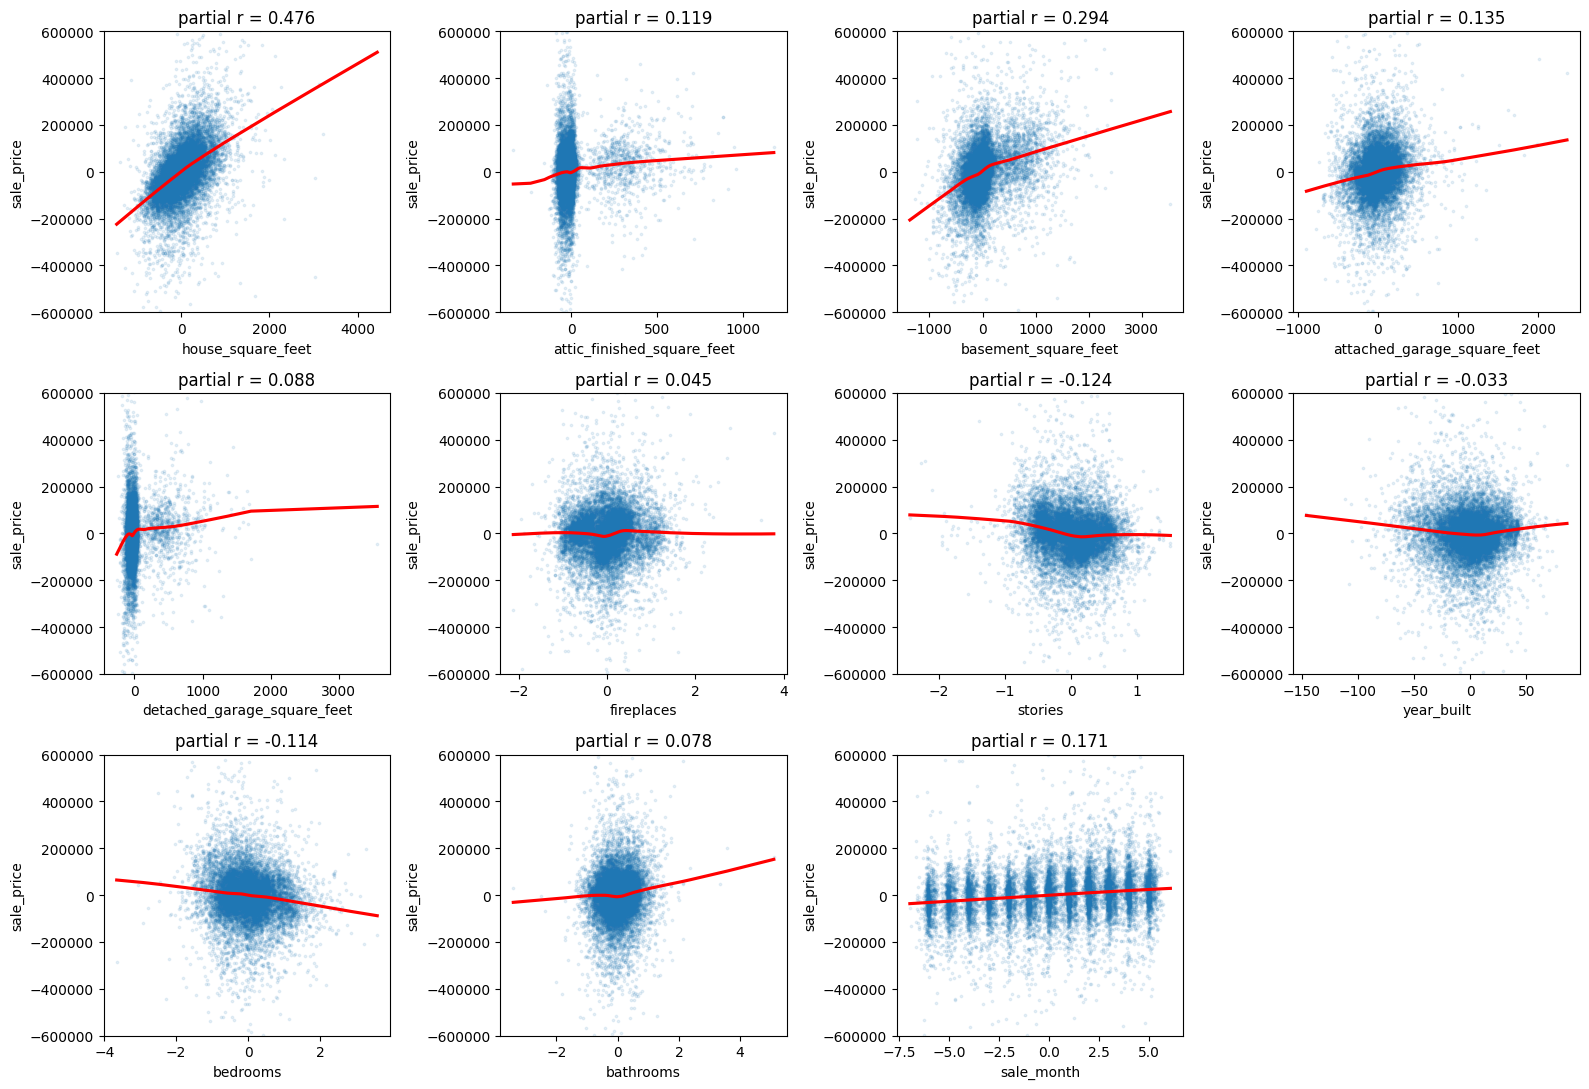

In [ ]:
#Question 5: Partial Correlation Plots
numeric_features = [
"house_square_feet",
"attic_finished_square_feet",
"basement_square_feet",
"attached_garage_square_feet",
"detached_garage_square_feet",
"fireplaces",
"stories",
"year_built",
"bedrooms",
"bathrooms",
"sale_month"
]

plt.figure(figsize=(16, 11))
for i, var in enumerate(numeric_features):
    others = X_train.drop(columns=var)
    price_left = y_train - LinearRegression().fit(others, y_train).predict(others)
    var_left = X_train[var] - LinearRegression().fit(others, X_train[var]).predict(others)
    plt.subplot(3, 4, i + 1)
    sns.regplot(x=var_left, y=price_left, lowess=True, scatter_kws={"alpha": 0.1, "s": 3}, line_kws={"color": "red"})
    plt.ylim(-600000, 600000)
    plt.xlabel(var)
    plt.ylabel("sale_price")
    plt.title("partial r = " + str(round(np.corrcoef(var_left, price_left)[0, 1], 3)))
plt.tight_layout()
plt.show()

For each numeric variable, the plot takes the linear effect of all the other features in Model 3 out of both sale price and that variable, and the red lowess curve shows any bend.

* house_square_feet: Strong positive relationship with sale price, with a partial correlation of 0.476, and close to linear.
* year_built: The clearest non-linear pattern. The curve is U-shaped, so the oldest and newest houses sell for more than mid-century houses with the same features. This motivates the age squared term in Question 6.
* basement_square_feet and detached_garage_square_feet: The curves climb steeply around zero and more slowly after, so having one adds more than each extra square foot.
* bedrooms vs bathrooms: Holding square footage constant, adding bedrooms lowers price, with a partial correlation of -0.114, since rooms get smaller. Bathrooms work the other way, and the curve bends upward, so extra bathrooms add more at the high end.

In [ ]:
# Question 6: Making a more complex model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Create complex features reflecting ideas from EDA & Question 5
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

for df_c in [X_train_complex, X_test_complex]:
# Non-linear transformations
    df_c["log_house_sqft"] = np.log(df_c["house_square_feet"])
    df_c["house_age"] = 2020 - df_c["year_built"]
    df_c["house_age_sq"] = df_c["house_age"] ** 2  # Captures vintage U-curve

# Interaction term
    df_c["sqft_x_bathrooms"] = df_c["house_square_feet"] * df_c["bathrooms"]

# house_age replaces year_built, since keeping both would repeat the same information
X_train_complex = X_train_complex.drop(columns="year_built")
X_test_complex = X_test_complex.drop(columns="year_built")

# Fit complex model on log price
model_complex = LinearRegression()
model_complex.fit(X_train_complex, np.log(y_train))

# Predict and turn the predictions back into dollars so they compare with Question 4
complex_train_pred = np.exp(model_complex.predict(X_train_complex))
complex_test_pred = np.exp(model_complex.predict(X_test_complex))

print("Complex Model with Transformations and Interactions:")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, complex_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, complex_test_pred)))
print("Training R²:", r2_score(y_train, complex_train_pred))
print("Test R²:", r2_score(y_test, complex_test_pred))

Complex Model with Transformations and Interactions:
Training RMSE: 113890.286254418
Test RMSE: 109032.8768585339
Training R²: 0.6886217535079987
Test R²: 0.6637356617789738


The complex model predicts log price and adds log house size, house age with age squared for the U shape in Question 5, and an interaction between house size and bathrooms. We turn the predictions back into dollars so they compare with Question 4. Compared with Model 3, training RMSE falls from \$117,144 to \$113,890 and training R² rises from 0.671 to 0.689. On the test set, RMSE only falls from \$109,345 to \$109,033 and R² only rises from 0.662 to 0.664. The complex model is the best so far, but most of its extra fit stays in the training data.

#Question 7

The house-size-only model underfits. Its R² is about 0.4 on both sets, so size alone misses most of what separates houses. Adding bedrooms and bathrooms helps only a little, while adding all features raises test R² to 0.662. Training and test results stay close for these simple models, so they are not overfitting. The complex model raises training R² from 0.671 to 0.689 but test R² only from 0.662 to 0.664, so the gap between training and test grows, an early sign of overfitting.

For model selection, training fit keeps improving as we add terms, so models have to be compared on data they were not fit on. Because we compared our models on the test set, it worked as validation data. A cleaner way is to choose among models with validation data or cross-validation inside the training set and keep the test set for one final evaluation.

In [ ]:
# Question 8: Lasso
from sklearn.linear_model import LassoCV

# Standardize with the training means and standard deviations so the penalty treats every feature alike
Z_train = (X_train_complex - X_train_complex.mean()) / X_train_complex.std()
Z_test = (X_test_complex - X_train_complex.mean()) / X_train_complex.std()

# Choose the penalty by 5-fold cross-validation on the training data
lasso = LassoCV(cv=5).fit(Z_train, np.log(y_train))
coef = pd.Series(lasso.coef_, index=Z_train.columns)
print("alpha:", lasso.alpha_)
print("Features kept:", (coef != 0).sum(), "of", len(coef))
print("Dropped:", coef[coef == 0].index.tolist())
print(coef.sort_values(key=abs, ascending=False).head(10))

# Predict and turn the predictions back into dollars
lasso_train_pred = np.exp(lasso.predict(Z_train))
lasso_test_pred = np.exp(lasso.predict(Z_test))

print("Lasso Model:")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, lasso_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, lasso_test_pred)))
print("Training R²:", r2_score(y_train, lasso_train_pred))
print("Test R²:", r2_score(y_test, lasso_test_pred))

alpha: 0.00025493145979121375
Features kept: 44 of 45
Dropped: ['exterior_Masonry Common Brick']
log_house_sqft                 0.128899
house_square_feet              0.106230
basement_square_feet           0.074433
house_age                     -0.068630
house_age_sq                   0.063094
waterfront_type_WF Salt        0.057063
bathrooms                      0.046322
waterfront_type_WF Lake        0.045041
sale_month                     0.043799
attached_garage_square_feet    0.040266
dtype: float64
Lasso Model:
Training RMSE: 113957.80696626529
Test RMSE: 109048.17845731026
Training R²: 0.6882524381992174
Test R²: 0.6636412729453632


We standardize the complex model's features with the training means and standard deviations so the penalty treats them alike, and let LassoCV choose the penalty by 5-fold cross-validation on the training data. The chosen alpha is about 0.00025, so the penalty is very small and the Lasso keeps 44 of the 45 features, dropping only the Masonry Common Brick exterior dummy. The largest standardized coefficients belong to log house size, house size, basement area, house age and age squared, salt water frontage and bathrooms. Its test RMSE is $109,048 and test R² is 0.664, with training R² 0.688, almost the same as the complex model without the penalty, so cross-validation found little to gain from shrinking this model.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b4753798e252a0929e56f317d3bb535f7c9f4407
- **AI tool and model used:** Cursor, GPT-5.6 Sol

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


1. Split the data before grouping rare categories or creating dummy variables; fit all preprocessing only on the training data to prevent test-data leakage.
2. Use validation data or cross-validation to select among Models 1–3 and the complex model. Reserve the test set for one final evaluation instead of repeatedly using it for model selection.
3. Correct the log-price model's retransformation. Simply applying `exp()` produces biased dollar-price predictions; apply a smearing correction or model price directly. Duan’s smearing factor corrects bias when converting predicted log prices back into dollars.
4. Replace the unsupported “multi-building sale” rule based only on adjacent rows sharing date and price. Verify sales using a genuine transaction/property identifier, or retain these rows if they cannot be reliably identified.
5. Put standardization and Lasso fitting inside a cross-validation pipeline so each validation fold is scaled using only its corresponding training fold.
6. Re-run every model and revise all reported RMSE, R², selected features, and conclusions after these corrections.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Preprocessing before splitting leaks test information. The revision learns rare categories and dummy columns from training data only. |
| 2 | Accept | Reusing the test set for selection makes its scores optimistic. The revision selects models with five-fold cross-validation and tests only after selection. |
| 3 | Accept | Directly exponentiating log predictions causes retransformation bias. The revision estimates and applies Duan's smearing factor. |
| 4 | Modify | Matching dates and prices do not prove that rows belong to one transaction. Because no transaction identifier exists, the revision retains these rows but still removes exact duplicates and invalid observations. |
| 5 | Accept | Scaling before cross-validation leaks information between folds. The revised Lasso pipeline fits its scaler separately inside every fold. |
| 6 | Accept | The corrections change the fitted samples and models. The revised code regenerates every metric, selected feature list, and conclusion. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Original dataset shape: (16814, 19)
Missing categorical values:
hvac_description        7
exterior                1
interior                7
roof_cover              8
waterfront_type     16261
view_quality        15895
utility_sewer           0
dtype: int64
Number of duplicate rows: 46
Number of suspicious observations removed: 140
Cleaned dataset shape: (16628, 19)
Remaining missing values: 0
count      16628.0
mean      460177.0
std       216383.0
min        25000.0
25%       349900.0
50%       417380.0
75%       523511.0
max      6130000.0
Name: sale_price, dtype: float64


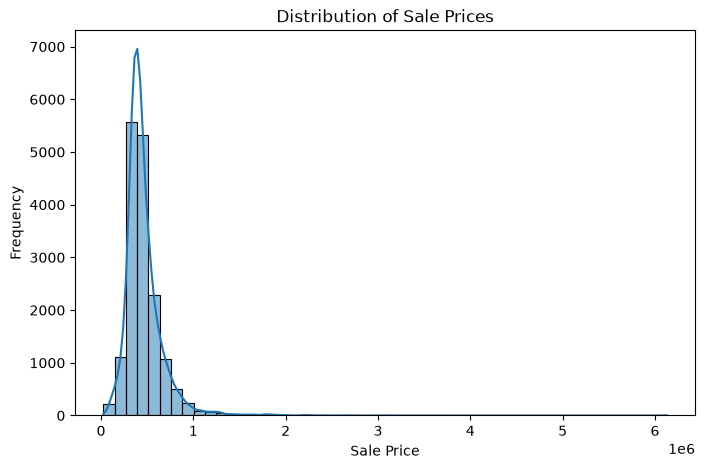

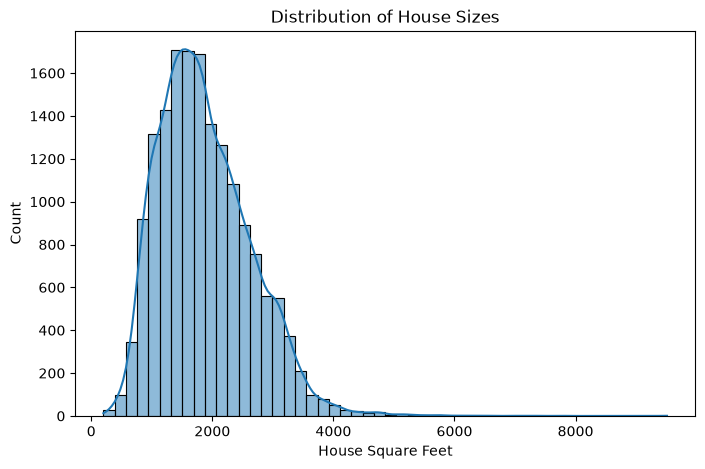

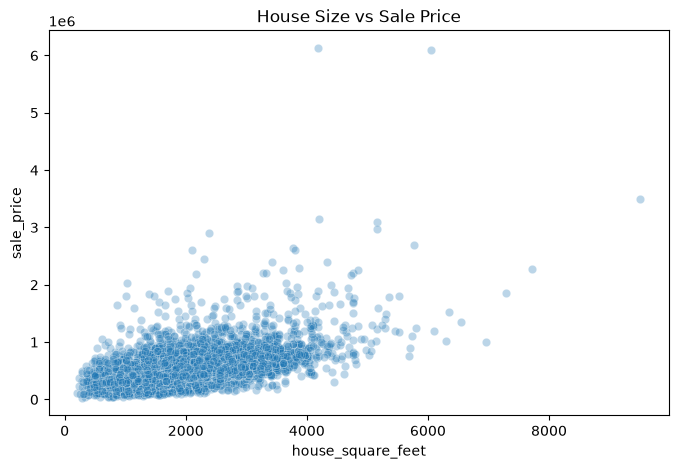

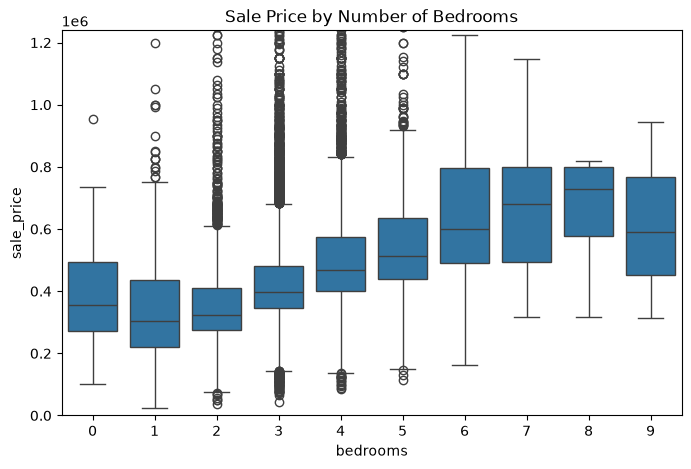

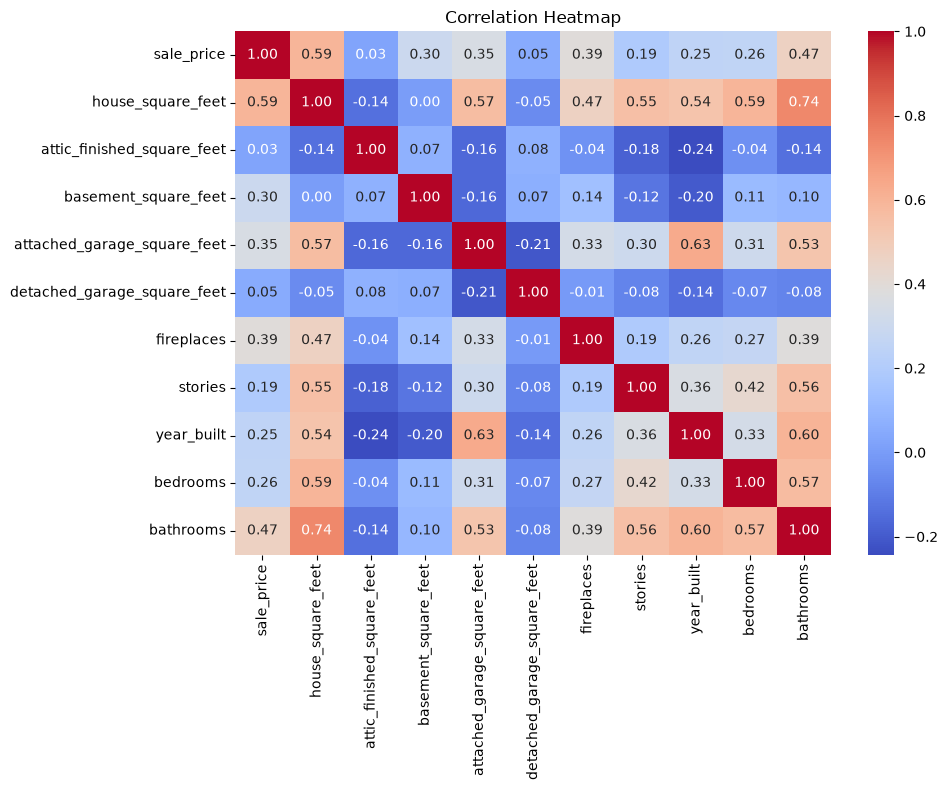

In [ ]:
# Question 1 - Cleaning and EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/L02-hedonic-pricing/data/pierce_county_house_sales.csv")
df["sale_date"] = pd.to_datetime(df["sale_date"])

categoricalcols = [
"hvac_description",
"exterior",
"interior",
"roof_cover",
"waterfront_type",
"view_quality",
"utility_sewer"
]

print("Original dataset shape:", df.shape)
print("Missing categorical values:")
print(df[categoricalcols].isnull().sum())


print("Number of duplicate rows:", df.duplicated().sum())
df_clean = df.drop_duplicates().copy()

# Remove suspicious observations
price_per_sqft = df_clean["sale_price"] / df_clean["house_square_feet"]
suspicious = (
    (df_clean["sale_price"] < 10000)
    | (df_clean["house_square_feet"] < 200)
    | (df_clean["year_built"] > df_clean["sale_date"].dt.year)
    | (price_per_sqft < 50)
    | (price_per_sqft > 2000)
    | (df_clean["bedrooms"] > 20)
)

print("Number of suspicious observations removed:", suspicious.sum())
df_clean = df_clean.loc[~suspicious].copy()

# A blank waterfront type or view means the house has none
df_clean["waterfront_type"] = df_clean["waterfront_type"].fillna("None")
df_clean["view_quality"] = df_clean["view_quality"].fillna("None")
df_clean["hvac_description"] = df_clean["hvac_description"].replace("Floor Wall Furnace", "Floor/Wall Furnace")

# Fill the few remaining missing categorical values
for col in categoricalcols:
    df_clean[col] = df_clean[col].fillna("Not recorded")

# Final cleaning checks
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print(df_clean["sale_price"].describe().round(0))

# Distribution of sale prices
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["sale_price"], bins=50, kde=True)
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# Distribution of house sizes
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["house_square_feet"], bins=50, kde=True)
plt.title("Distribution of House Sizes")
plt.xlabel("House Square Feet")
plt.show()

# House size vs sale price
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="house_square_feet",
    y="sale_price",
    alpha=0.3
)
plt.title("House Size vs Sale Price")
plt.show()

# Bedrooms vs sale price
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="bedrooms", y="sale_price")
plt.ylim(0, df_clean["sale_price"].quantile(0.99))
plt.title("Sale Price by Number of Bedrooms")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_clean.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

The raw data have 16,814 rows. Most of the missing values are in waterfront_type and view_quality, and a blank there means the house has no waterfront or view, so we fill them with None. The few blanks in the other building descriptions become Not recorded, so no missing values remain.

The original multi-building rule was removed because matching dates and prices do not prove that adjacent rows belong to one transaction. Without a transaction identifier, removing them could discard valid sales. We still remove 46 exact duplicates and 140 suspicious observations, leaving 16,628 rows.

Sale prices are right-skewed. The median is $417,380, the mean is higher at $460,177, and the most expensive sale is $6,130,000. Price rises with house size, and the spread gets wider for bigger houses. In the heatmap, house size has the strongest correlation with price at 0.59, followed by bathrooms at 0.47.

In [ ]:
# Question 2 - Variable transformation
from sklearn.model_selection import train_test_split

df_clean["sale_month"] = df_clean["sale_date"].dt.month
X_raw = df_clean.drop(columns=["sale_price"])
y = df_clean["sale_price"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42
)

for col in ["hvac_description", "exterior", "interior", "roof_cover", "utility_sewer"]:
    counts = X_train_raw[col].value_counts()
    rare_levels = counts[counts < 50].index
    X_train_raw.loc[X_train_raw[col].isin(rare_levels), col] = "Other"
    X_test_raw.loc[X_test_raw[col].isin(rare_levels), col] = "Other"

X_train = X_train_raw.drop(columns="sale_date")
X_test = X_test_raw.drop(columns="sale_date")
X_train = pd.get_dummies(X_train, columns=categoricalcols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categoricalcols, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training X shape:", X_train.shape)
print("Test X shape:", X_test.shape)
print("Missing values:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Training X shape: (13302, 41)
Test X shape: (3326, 41)
Missing values: 0


In [19]:
# Question 3 - Confirm the 80/20 split created before preprocessing
print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (13302, 41) (13302,)
Test set: (3326, 41) (3326,)


In [ ]:
# Question 4: Simple linear models
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
import numpy as np

# Model 1: House size only
model1 = LinearRegression()
model1.fit(X_train[["house_square_feet"]], y_train)
model1_train_pred = model1.predict(X_train[["house_square_feet"]])
model1_test_pred = model1.predict(X_test[["house_square_feet"]])

print("Model 1: House Size Only")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, model1_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, model1_test_pred)))
print("Training R²:", r2_score(y_train, model1_train_pred))
print("Test R²:", r2_score(y_test, model1_test_pred))

# Model 2: House size, bedrooms, and bathrooms
features2 = ["house_square_feet", "bedrooms", "bathrooms"]
model2 = LinearRegression()
model2.fit(X_train[features2], y_train)
model2_train_pred = model2.predict(X_train[features2])
model2_test_pred = model2.predict(X_test[features2])

print("\nModel 2: House Size, Bedrooms, and Bathrooms")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, model2_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, model2_test_pred)))
print("Training R²:", r2_score(y_train, model2_train_pred))
print("Test R²:", r2_score(y_test, model2_test_pred))

# Model 3: All available features
model3 = LinearRegression()
model3.fit(X_train, y_train)
model3_train_pred = model3.predict(X_train)
model3_test_pred = model3.predict(X_test)

print("\nModel 3: All Features")
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, model3_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, model3_test_pred)))
print("Training R²:", r2_score(y_train, model3_train_pred))
print("Test R²:", r2_score(y_test, model3_test_pred))

cv = KFold(n_splits=5, shuffle=True, random_state=42)
feature_sets = {
    "Model 1": ["house_square_feet"],
    "Model 2": features2,
    "Model 3": list(X_train.columns)
}
cv_rows = []
for name, features in feature_sets.items():
    scores = cross_validate(
        LinearRegression(), X_train[features], y_train, cv=cv,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )
    cv_rows.append([name, -scores["test_rmse"].mean(), scores["test_r2"].mean()])
cv_results = pd.DataFrame(cv_rows, columns=["Model", "CV RMSE", "CV R²"])
print("\nTraining-only cross-validation:")
print(cv_results.sort_values("CV RMSE"))

Model 1: House Size Only
Training RMSE: 178849.7985043642
Test RMSE: 153761.3437538846
Training R²: 0.34689351248957967
Test R²: 0.3793219343601699

Model 2: House Size, Bedrooms, and Bathrooms
Training RMSE: 176336.72283195305
Test RMSE: 150644.66937915428
Training R²: 0.3651185793462973
Test R²: 0.40422866499053334

Model 3: All Features
Training RMSE: 135882.8016561117
Test RMSE: 122016.13050438541
Training R²: 0.623004581268745
Test R²: 0.609153198095497

Training-only cross-validation:
     Model        CV RMSE     CV R²
2  Model 3  136980.357145  0.616430
1  Model 2  176297.845584  0.364712
0  Model 1  178733.141951  0.347064


The house-size-only model provides a useful baseline but does not account for other characteristics that can impact its price. Adding bedrooms and bathrooms improves the model only slightly, raising test R² from 0.379 to 0.404. Overall, Model 3 performs best because it has the lowest training-only cross-validation RMSE at $136,980 and the highest cross-validation R² at 0.616. Its final test RMSE is $122,016 and test R² is 0.609. Training and test results are reasonably close for all three models, so none shows serious overfitting.

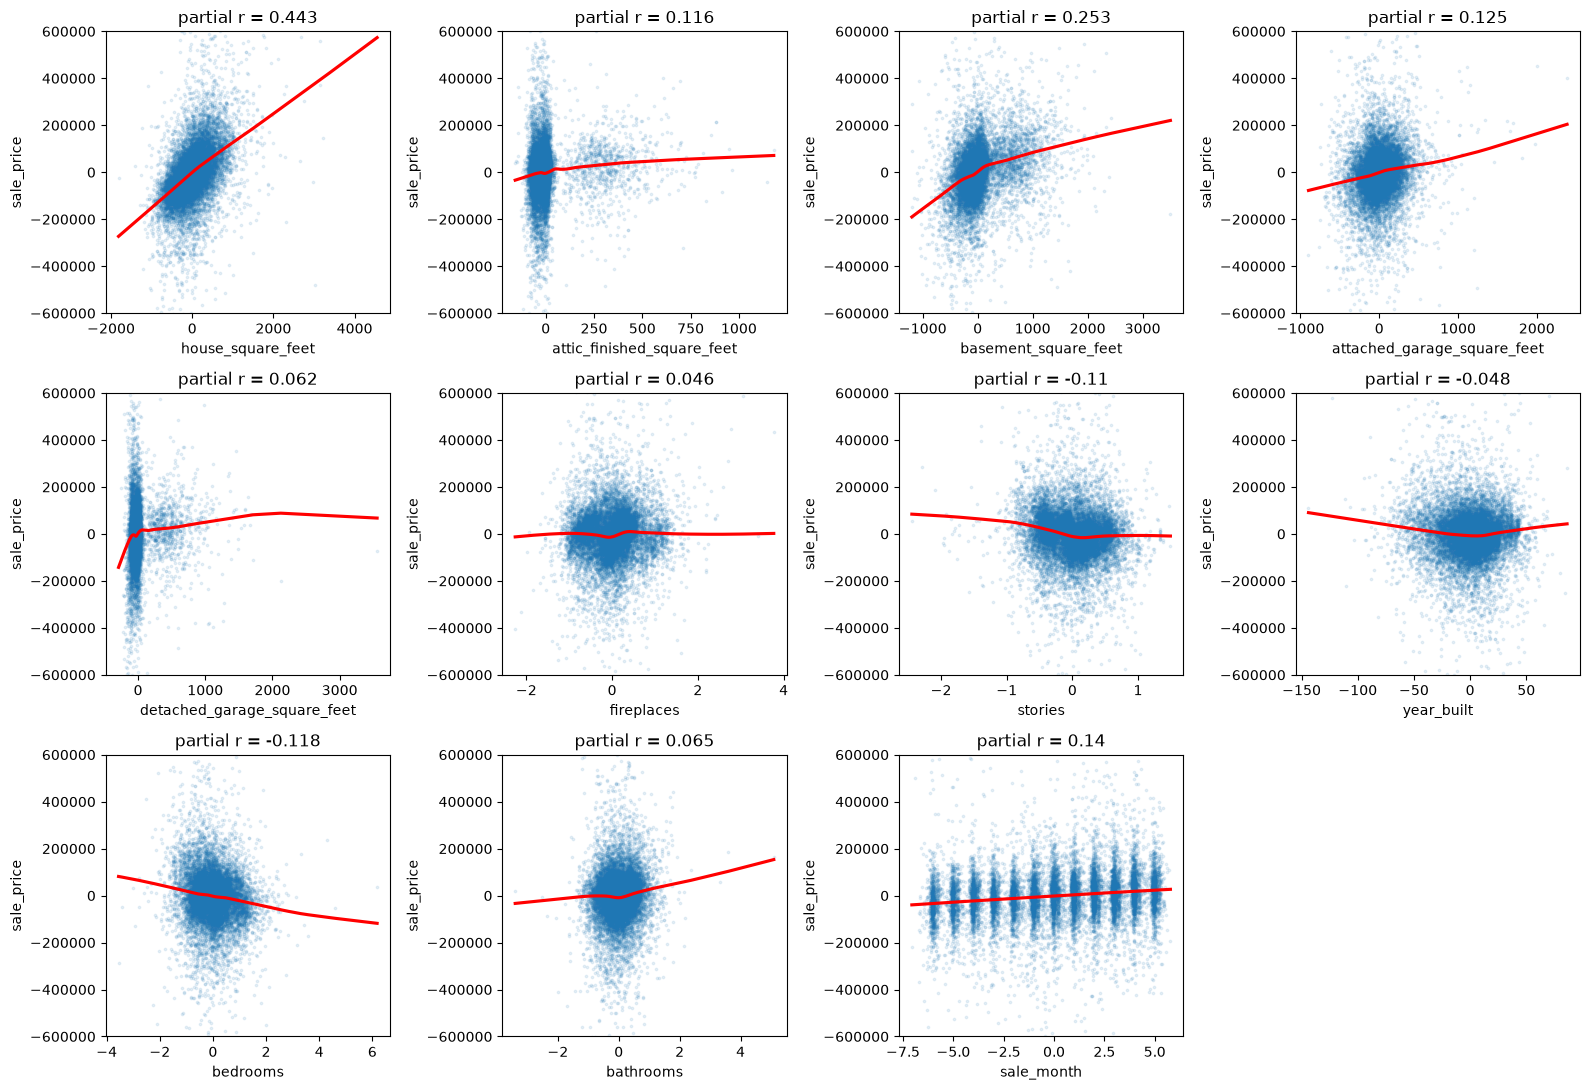

In [ ]:
# Question 5
numeric_features = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces",
    "stories", "year_built", "bedrooms", "bathrooms", "sale_month"
]

plt.figure(figsize=(16, 11))
for i, var in enumerate(numeric_features):
    others = X_train.drop(columns=var)
    price_left = y_train - LinearRegression().fit(others, y_train).predict(others)
    var_left = X_train[var] - LinearRegression().fit(others, X_train[var]).predict(others)
    plt.subplot(3, 4, i + 1)
    sns.regplot(x=var_left, y=price_left, lowess=True,
                scatter_kws={"alpha": 0.1, "s": 3},
                line_kws={"color": "red"})
    plt.ylim(-600000, 600000)
    plt.xlabel(var)
    plt.ylabel("sale_price")
    plt.title("partial r = " + str(round(np.corrcoef(var_left, price_left)[0, 1], 3)))
plt.tight_layout()
plt.show()

For each numeric variable, the plot takes the linear effect of all the other features in Model 3 out of both sale price and that variable, and the red lowess curve shows any bend.

* house_square_feet: Strong positive relationship with sale price, with a partial correlation of 0.443, and close to linear.
* year_built: The clearest non-linear pattern. The curve is U-shaped, so the oldest and newest houses sell for more than mid-century houses with the same features. This motivates the age squared term in Question 6.
* basement_square_feet and detached_garage_square_feet: The curves climb steeply around zero and more slowly after, so having one adds more than each extra square foot.
* bedrooms vs bathrooms: Holding square footage constant, adding bedrooms lowers price, with a partial correlation of -0.118, since rooms get smaller. Bathrooms work the other way, and the curve bends upward, so extra bathrooms add more at the high end.

In [22]:
# Question 6: Making a more complex model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import BaseEstimator, RegressorMixin
import numpy as np


X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

for df_c in [X_train_complex, X_test_complex]:
    # Non-linear transformations
    df_c["log_house_sqft"] = np.log(df_c["house_square_feet"])
    df_c["house_age"] = 2020 - df_c["year_built"]
    df_c["house_age_sq"] = df_c["house_age"] ** 2

    # Interaction term
    df_c["sqft_x_bathrooms"] = df_c["house_square_feet"] * df_c["bathrooms"]

# house_age replaces year_built
X_train_complex = X_train_complex.drop(columns="year_built")
X_test_complex = X_test_complex.drop(columns="year_built")


model_complex = LinearRegression()
model_complex.fit(X_train_complex, np.log(y_train))


complex_train_log_pred = model_complex.predict(X_train_complex)
complex_test_log_pred = model_complex.predict(X_test_complex)
smearing_factor = np.mean(np.exp(np.log(y_train) - complex_train_log_pred))
complex_train_pred = smearing_factor * np.exp(complex_train_log_pred)
complex_test_pred = smearing_factor * np.exp(complex_test_log_pred)

print("Complex Model with Transformations and Interactions:")
print("Smearing factor:", smearing_factor)
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, complex_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, complex_test_pred)))
print("Training R²:", r2_score(y_train, complex_train_pred))
print("Test R²:", r2_score(y_test, complex_test_pred))


class SmearingLogRegression(RegressorMixin, BaseEstimator):
    def fit(self, X, y):
        log_y = np.log(y)
        self.model_ = LinearRegression().fit(X, log_y)
        self.smearing_ = np.mean(np.exp(log_y - self.model_.predict(X)))
        return self

    def predict(self, X):
        return self.smearing_ * np.exp(self.model_.predict(X))

complex_cv = cross_validate(
    SmearingLogRegression(), X_train_complex, y_train, cv=cv,
    scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}
)
print("Complex CV RMSE:", -complex_cv["test_rmse"].mean())
print("Complex CV R²:", complex_cv["test_r2"].mean())

Complex Model with Transformations and Interactions:
Smearing factor: 1.0302811678289252
Training RMSE: 129112.74106868313
Test RMSE: 115932.2428650226
Training R²: 0.659634690335738
Test R²: 0.6471577828267333
Complex CV RMSE: 131132.34621861656
Complex CV R²: 0.6482385981895848


The complex model predicts log price and adds log house size, house age with age squared for the U shape in Question 5, and an interaction between house size and bathrooms. Duan's smearing factor of 1.0303 corrects the bias that would result from directly exponentiating log predictions. Compared with Model 3, training RMSE falls from $135,883 to $129,113 and test RMSE falls from $122,016 to $115,932. Its training-only CV RMSE is also lower, falling from $136,980 to $131,132, so the complex model is selected without using the test results.

Question 7

The house-size-only model underfits. Its R² is below 0.4 on both sets, so size alone misses most of what separates houses. Adding bedrooms and bathrooms helps only a little, while adding all features raises test R² to 0.609. Training and test results stay close for these simple models, so they are not seriously overfitting. The complex model improves test R² further to 0.647.

For model selection, training fit keeps improving as we add terms, so models have to be compared on data they were not fit on. The revised solution uses five-fold cross-validation inside the training set and keeps the test set for final evaluation. The complex model is selected because its CV RMSE of $131,132 is lower than Model 3's $136,980.

In [ ]:
# Question 8 - Lasso
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

lasso_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("lasso", Lasso(max_iter=50000))
])
lasso_search = GridSearchCV(
    lasso_pipeline,
    {"lasso__alpha": np.logspace(-5, -1, 50)},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)
lasso_search.fit(X_train_complex, np.log(y_train))

best_lasso = lasso_search.best_estimator_
coef = pd.Series(best_lasso.named_steps["lasso"].coef_, index=X_train_complex.columns)
log_train_pred = best_lasso.predict(X_train_complex)
log_test_pred = best_lasso.predict(X_test_complex)
lasso_smearing = np.mean(np.exp(np.log(y_train) - log_train_pred))
lasso_train_pred = lasso_smearing * np.exp(log_train_pred)
lasso_test_pred = lasso_smearing * np.exp(log_test_pred)

print("alpha:", lasso_search.best_params_["lasso__alpha"])
print("Features kept:", (coef != 0).sum(), "of", len(coef))
print("Dropped:", coef[coef == 0].index.tolist())
print(coef[coef != 0].sort_values(key=abs, ascending=False).head(10))
print("Training RMSE:", np.sqrt(mean_squared_error(y_train, lasso_train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, lasso_test_pred)))
print("Training R²:", r2_score(y_train, lasso_train_pred))
print("Test R²:", r2_score(y_test, lasso_test_pred))

alpha: 0.00016768329368110067
Features kept: 43 of 44
Dropped: ['roof_cover_Composition Shingle']
house_square_feet              0.179341
house_age                     -0.072227
basement_square_feet           0.071977
waterfront_type_WF Salt        0.069017
house_age_sq                   0.068523
log_house_sqft                 0.067285
sqft_x_bathrooms              -0.065036
bathrooms                      0.061311
waterfront_type_WF Lake        0.050302
attached_garage_square_feet    0.042361
dtype: float64
Training RMSE: 129154.37762070828
Test RMSE: 115882.82017417409
Training R²: 0.6594151314780128
Test R²: 0.6474585566982807


We standardize the complex model's features inside each cross-validation fold so the penalty treats them alike without leaking validation-fold information. Cross-validation chooses an alpha of about 0.00017. The Lasso keeps 43 of the 44 features, dropping only the Composition Shingle roof-cover dummy. The largest standardized coefficients belong to house size, house age, basement area, salt-water frontage, age squared, log house size, the size–bathrooms interaction, and bathrooms. Its test RMSE is $115,883 and test R² is 0.647, almost the same as the complex model without the penalty, so regularization provides little additional improvement.

### *Reflection on AI assistance
In your own words without generative AI.

Overall, the AI was very good at identifying any mistakes that were subtle to the output but had an impact on the project. It also made improvments to the visualizations and explanations of the outputs. The main improvements were preventing data leakage during preprocessing, using cross-validation for model selection, correcting log-price predictions, and scaling the Lasso model within each validation fold. We verified these changes by rerunning the notebook, checking that every model produced updated RMSE and R² values, and made sure hhat the visualizations were correct. One remaining concern is that the dataset has no transaction identifier, making it difficult to determine whether rows with matching dates and prices represent one multi-building sale. In the end, the revised models produced more reliable results while keeping the original analysis and structure mostly similar to before just more accurate. Overall, the AI was useful for finding technical problems, but its suggestions still needed to be reviewed for overcomplextiy and sometimes wanted to do too much. 